In [1]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px

sns.set_theme(style='whitegrid')
print('numpy', np.__version__)
print('pandas', pd.__version__)
print('matplotlib', matplotlib.__version__)
print('seaborn', sns.__version__)
print('plotly', plotly.__version__)

numpy 2.5.2
pandas 3.0.5
matplotlib 3.11.1
seaborn 0.13.2
plotly 7.0.0


### EJERCICIO 2

Dataset utilizado: online_retail_II

En esta celda se importan las librerías que se usan en todo el notebook: NumPy para cálculos numéricos, Pandas para cargar y manipular el dataset, Matplotlib y Seaborn para los gráficos estáticos del ejercicio 2 y Plotly Express para los gráficos interactivos del ejercicio 3. Con sns.set_theme se define un estilo con cuadrícula blanca para que todos los gráficos de Seaborn y Matplotlib se vean uniformes, y al final se imprimen las versiones instaladas para dejar constancia del entorno en el que se ejecutó el análisis.

In [2]:
df = pd.read_csv('online_retail_II.csv', encoding='ISO-8859-1')
df = df.rename(columns={'Customer ID': 'Customer_ID'})

print('Filas:', len(df))
print('Columnas:', list(df.columns))
print()
print(df.dtypes)
df.head()

Filas: 1067371
Columnas: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer_ID', 'Country']

Invoice            str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
Price          float64
Customer_ID    float64
Country            str
dtype: object


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer_ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


Aquí se carga el archivo online_retail_II.csv con Pandas usando la codificación ISO-8859-1, porque el archivo contiene caracteres que no son UTF-8 en las descripciones de los productos. Se renombra la columna Customer ID a Customer_ID para quitar el espacio y facilitar su uso. Después se imprime el número de filas, la lista de columnas y el tipo de dato de cada una, y con head() se muestran los primeros registros para ver cómo luce cada transacción: factura, código de producto, descripción, cantidad, fecha, precio unitario, cliente y país.

In [3]:
df = df.dropna(subset=['Customer_ID'])
df = df[df['Quantity'] > 0]
df = df[df['Price'] > 0]
df['Total'] = df['Quantity'] * df['Price']

df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Hora'] = df['InvoiceDate'].dt.hour
df['Mes'] = df['InvoiceDate'].dt.month

print('Filas después de limpiar:', len(df))
print('Total vendido:', round(df['Total'].sum()))
df[['Quantity', 'Price', 'Total']].describe().round(2)

Filas después de limpiar: 805549
Total vendido: 17743429


,Quantity,Price,Total
count,805549.00,805549.00,805549.00
mean,13.29,3.21,22.03
std,143.63,29.20,224.04
min,1.00,0.00,0.00
25%,2.00,1.25,4.95
50%,5.00,1.95,11.85
75%,12.00,3.75,19.50
max,80995.00,10953.50,168469.60


Esta celda limpia el dataset antes de graficar. Se eliminan las filas sin cliente, las cantidades negativas o cero (que corresponden a devoluciones y cancelaciones) y los precios iguales o menores a cero (ajustes contables), porque distorsionarían cualquier promedio o distribución. Luego se crea la columna Total como cantidad por precio, que representa el valor de cada línea de venta. También se convierte InvoiceDate a fecha y se extraen la hora y el mes como variables numéricas adicionales, para tener más variables en el heatmap de correlación. Por último se imprime cuántas filas quedan, el total vendido y un describe() de las tres variables principales, que ya deja ver que la media está muy por encima de la mediana y que los máximos son extremos.

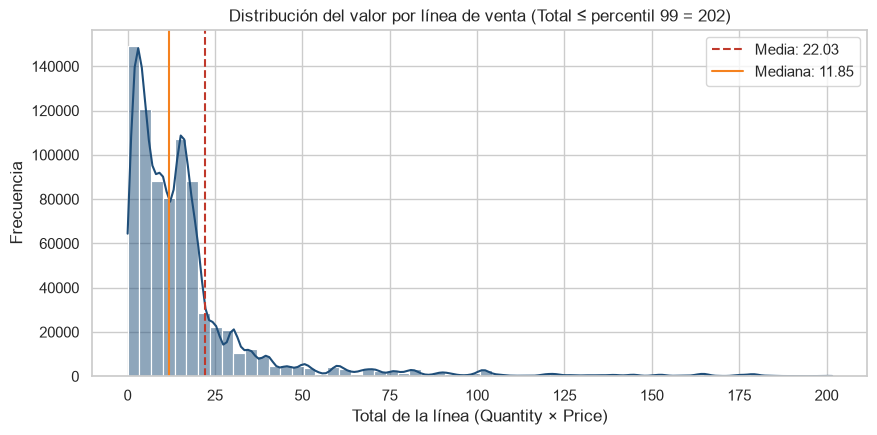

Registros mostrados: 797520 de 805549 (99.0%)
Asimetría (skew) de Total completo: 586.62


In [4]:
# Ejercicio 2 - Histograma
limite = df['Total'].quantile(0.99)
valores = df.loc[df['Total'] <= limite, 'Total']

plt.figure(figsize=(10, 4.5))
sns.histplot(valores, bins=60, kde=True, color='#1F4E79')
plt.axvline(df['Total'].mean(), color='#C0392B', linestyle='--', label=f"Media: {df['Total'].mean():.2f}")
plt.axvline(df['Total'].median(), color='#F5821F', linestyle='-', label=f"Mediana: {df['Total'].median():.2f}")
plt.title(f'Distribución del valor por línea de venta (Total ≤ percentil 99 = {limite:.0f})')
plt.xlabel('Total de la línea (Quantity × Price)')
plt.ylabel('Frecuencia')
plt.legend()
plt.show()

print('Registros mostrados:', len(valores), 'de', len(df), f'({len(valores) / len(df):.1%})')
print('Asimetría (skew) de Total completo:', round(df['Total'].skew(), 2))

Este es el histograma de la variable Total. Como existen ventas enormes (el máximo supera los 168.000), un histograma con todo el rango se vería como una sola barra pegada al cero, así que el rango se ajusta al percentil 99: se calcula ese valor con quantile(0.99) y solo se grafican los registros por debajo de él, que siguen siendo el 99% de los datos. Se usa sns.histplot con 60 intervalos y la curva de densidad (kde) para ver mejor la forma. Además se dibujan dos líneas verticales, una para la media y otra para la mediana, porque su separación ayuda a identificar el sesgo. El gráfico lleva título y nombres en ambos ejes, y al final se imprime cuántos registros se muestran y el coeficiente de asimetría calculado sobre todos los datos.

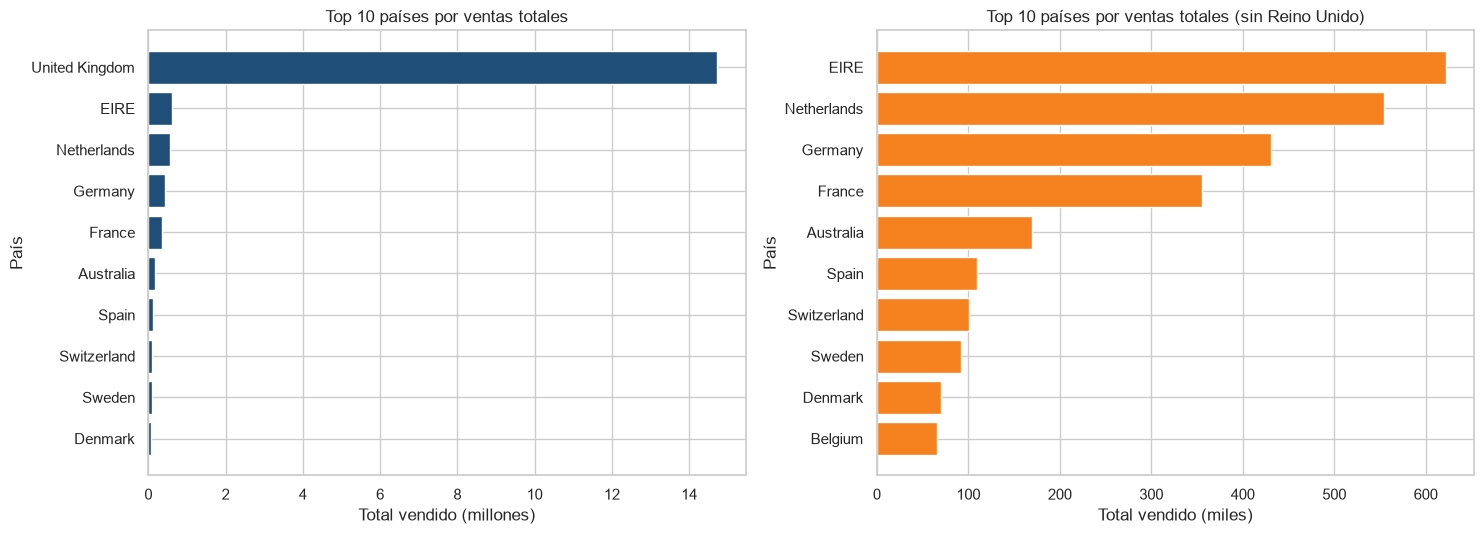

Participación (%) sobre el total vendido:
Country
United Kingdom    82.98
EIRE               3.50
Netherlands        3.12
Germany            2.43
France             2.00
Australia          0.96
Spain              0.62
Switzerland        0.57
Sweden             0.52
Denmark            0.39
Name: Total, dtype: float64


In [5]:
# Ejercicio 2 - Barras (top 10)
ventas_pais = df.groupby('Country')['Total'].sum().sort_values(ascending=False)
top10 = ventas_pais.head(10)
top10_sin_uk = ventas_pais.drop('United Kingdom').head(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

axes[0].barh(top10.index[::-1], top10.values[::-1] / 1e6, color='#1F4E79')
axes[0].set_title('Top 10 países por ventas totales')
axes[0].set_xlabel('Total vendido (millones)')
axes[0].set_ylabel('País')

axes[1].barh(top10_sin_uk.index[::-1], top10_sin_uk.values[::-1] / 1e3, color='#F5821F')
axes[1].set_title('Top 10 países por ventas totales (sin Reino Unido)')
axes[1].set_xlabel('Total vendido (miles)')
axes[1].set_ylabel('País')

plt.tight_layout()
plt.show()

participacion = (top10 / ventas_pais.sum() * 100).round(2)
print('Participación (%) sobre el total vendido:')
print(participacion)

Aquí se construye el gráfico de barras con la suma de ventas por país, que es la categoría del dataset. Primero se agrupa por Country, se suma la columna Total y se ordena de mayor a menor. Se hacen dos paneles: el de la izquierda muestra el top 10 completo en millones, y el de la derecha muestra el top 10 excluyendo al Reino Unido en miles, porque el Reino Unido es tan grande que aplasta visualmente a los demás países y no deja comparar el resto. Se usan barras horizontales para que los nombres de los países se lean bien y se invierte el orden con [::-1] para que el país con más ventas quede arriba. Cada panel tiene su título y sus ejes con nombre, y debajo se imprime el porcentaje que representa cada país dentro del total vendido.

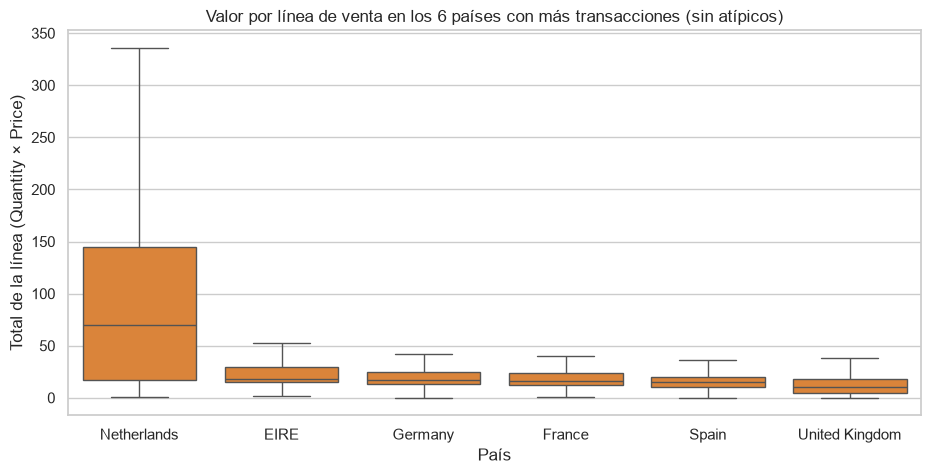

,count,mean,25%,50%,75%
Country,,,,,
Netherlands,5088.0,108.93,17.00,69.6,145.0
EIRE,15743.0,39.49,14.85,17.7,30.0
Germany,16694.0,25.83,13.20,17.4,24.9
France,13812.0,25.72,11.90,16.5,23.4
Spain,3719.0,29.36,10.08,15.0,20.4
United Kingdom,725250.0,20.30,4.20,10.2,17.7


In [6]:
# Ejercicio 2 - Boxplot por categoría
top6 = df['Country'].value_counts().head(6).index
sub = df[df['Country'].isin(top6)]
orden = sub.groupby('Country')['Total'].median().sort_values(ascending=False).index

plt.figure(figsize=(11, 5))
sns.boxplot(data=sub, x='Country', y='Total', order=orden, showfliers=False, color='#F5821F')
plt.title('Valor por línea de venta en los 6 países con más transacciones (sin atípicos)')
plt.xlabel('País')
plt.ylabel('Total de la línea (Quantity × Price)')
plt.show()

sub.groupby('Country')['Total'].describe()[['count', 'mean', '25%', '50%', '75%']].loc[orden].round(2)

En esta celda se hace el boxplot de Total por país. Se toman los 6 países con más transacciones usando value_counts, para que cada caja se construya con suficientes datos, y se ordenan las cajas de mayor a menor según su mediana para facilitar la comparación. Se usa showfliers=False porque los valores atípicos son tan grandes que, si se dibujan, la caja queda comprimida en el fondo del gráfico y no se puede leer. El gráfico tiene título y nombre en los dos ejes. Debajo se muestra una tabla de apoyo con la cantidad de registros, la media y los cuartiles de cada país, para poder leer con precisión lo que se ve en las cajas.

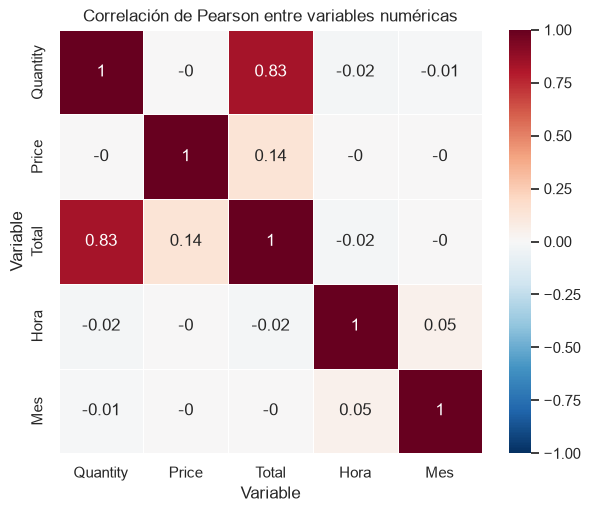

Pares ordenados por |correlación|:
Quantity  Total    0.83
Price     Total    0.14
Hora      Mes      0.05
Total     Hora    -0.02
Quantity  Hora    -0.02
          Mes     -0.01
          Price   -0.00
Price     Hora    -0.00
          Mes     -0.00
Total     Mes     -0.00
dtype: float64


In [7]:
# Ejercicio 2 - Heatmap de correlación
numericas = ['Quantity', 'Price', 'Total', 'Hora', 'Mes']
corr = df[numericas].corr().round(2)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True, linewidths=0.5)
plt.title('Correlación de Pearson entre variables numéricas')
plt.xlabel('Variable')
plt.ylabel('Variable')
plt.show()

pares = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna().sort_values(key=abs, ascending=False)
print('Pares ordenados por |correlación|:')
print(pares)

Esta celda calcula la matriz de correlación de Pearson entre las variables numéricas del dataset: cantidad, precio, total, y la hora y el mes de la compra. Customer_ID no se incluye porque es un identificador y su valor numérico no tiene significado. El heatmap usa una escala divergente de azul a rojo centrada en cero y fijada entre -1 y 1, de modo que el color indica tanto la fuerza como el signo de la relación, y con annot=True se escribe el valor en cada celda. Se agregan título y nombres en los ejes. Al final, se toma solo el triángulo superior de la matriz para no repetir pares y se ordenan por valor absoluto, así se identifica de forma directa cuál es el par con mayor correlación.

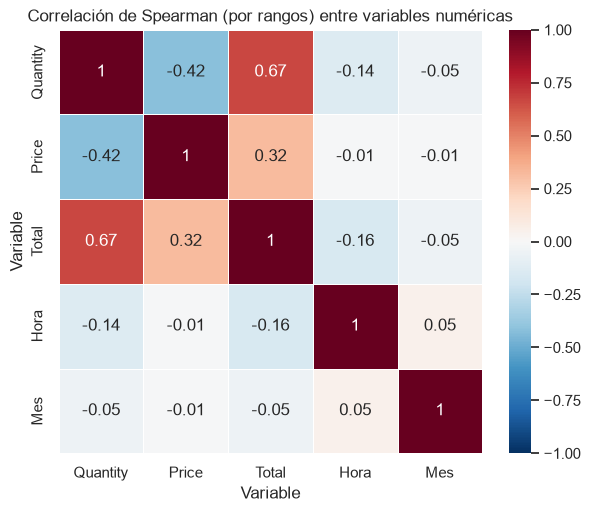

Pares ordenados por |correlación| (Spearman):
Quantity  Total    0.67
          Price   -0.42
Price     Total    0.32
Total     Hora    -0.16
Quantity  Hora    -0.14
dtype: float64


In [8]:
corr_spearman = df[numericas].corr(method='spearman').round(2)

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_spearman, annot=True, cmap='RdBu_r', vmin=-1, vmax=1, center=0, square=True, linewidths=0.5)
plt.title('Correlación de Spearman (por rangos) entre variables numéricas')
plt.xlabel('Variable')
plt.ylabel('Variable')
plt.show()

pares_s = corr_spearman.where(np.triu(np.ones(corr_spearman.shape, dtype=bool), k=1)).stack().dropna().sort_values(key=abs, ascending=False)
print('Pares ordenados por |correlación| (Spearman):')
print(pares_s.head(5))

Como complemento se repite el heatmap con la correlación de Spearman, que trabaja con el orden de los valores en lugar de los valores en sí. Esto es útil en este dataset porque Pearson es muy sensible a los valores extremos, y aquí hay ventas con cantidades y precios gigantes que pueden inflar o esconder una relación. Comparar ambos mapas permite ver qué relaciones se mantienen cuando se elimina el efecto de los atípicos.

In [9]:
# Ejercicio 3 - Barras interactivas
resumen = (df.groupby('Country')
             .agg(Total=('Total', 'sum'),
                  Facturas=('Invoice', 'nunique'),
                  Clientes=('Customer_ID', 'nunique'))
             .reset_index())
resumen['Ticket_promedio'] = (resumen['Total'] / resumen['Facturas']).round(2)
top10_int = resumen.sort_values('Total', ascending=False).head(10)

fig_barras = px.bar(top10_int, x='Total', y='Country', orientation='h', color='Total',
                    color_continuous_scale='Blues',
                    hover_data={'Facturas': True, 'Clientes': True, 'Ticket_promedio': ':.2f', 'Total': ':,.0f'},
                    title='Top 10 países por ventas totales (interactivo)',
                    labels={'Total': 'Total vendido', 'Country': 'País',
                            'Ticket_promedio': 'Ticket promedio por factura'})
fig_barras.update_layout(yaxis={'categoryorder': 'total ascending'}, height=500)
fig_barras.show()

top10_int.round(2)

,Country,Total,Facturas,Clientes,Ticket_promedio
38,United Kingdom,14723147.52,33541,5350,438.96
10,EIRE,621631.11,567,5,1096.35
24,Netherlands,554232.34,228,22,2430.84
14,Germany,431262.46,789,107,546.59
13,France,355257.47,614,95,578.60
0,Australia,169968.11,95,15,1789.14
32,Spain,109178.53,154,41,708.95
34,Switzerland,100365.34,90,22,1115.17
33,Sweden,91549.72,104,19,880.29
9,Denmark,69862.19,43,12,1624.70


Aquí empieza el ejercicio 3 con el gráfico de barras interactivo. Primero se construye una tabla resumen por país con agg: la suma de ventas, el número de facturas distintas y el número de clientes distintos, y a partir de ellas se calcula el ticket promedio por factura. Luego se toman los 10 países con más ventas y se grafican con px.bar en horizontal, coloreando las barras según el total. Lo importante es hover_data, que hace que al pasar el mouse sobre cada barra aparezcan las facturas, los clientes y el ticket promedio, información que en un gráfico estático no cabría. Con labels se ponen los nombres de los ejes en español y con categoryorder se ordenan las barras de mayor a menor. Además, al ser Plotly, se puede hacer zoom, ocultar elementos o hacer doble clic para restaurar la vista. Debajo del gráfico se deja la tabla resumen con los mismos datos para poder consultarlos sin interactuar.

In [10]:
# Ejercicio 3 - Dispersión interactiva (muestra)
muestra = df.sample(5000, random_state=42).copy()
top5 = df['Country'].value_counts().head(5).index
muestra['Grupo_pais'] = np.where(muestra['Country'].isin(top5), muestra['Country'], 'Otros')

fig_disp = px.scatter(muestra, x='Quantity', y='Price', color='Grupo_pais',
                      log_x=True, log_y=True, opacity=0.5,
                      hover_data=['Description', 'Country', 'Total', 'InvoiceDate'],
                      title='Cantidad vs Precio unitario (muestra de 5.000 líneas, escala logarítmica)',
                      labels={'Quantity': 'Cantidad (log)', 'Price': 'Precio unitario (log)',
                              'Grupo_pais': 'País'})
fig_disp.update_layout(height=550)
fig_disp.show()

print('Correlación de Spearman en la muestra:', round(muestra[['Quantity', 'Price']].corr(method='spearman').iloc[0, 1], 2))

Correlación de Spearman en la muestra: -0.42


Esta celda crea la dispersión interactiva entre cantidad y precio unitario. Como el dataset limpio tiene más de 800 mil filas, se toma una muestra aleatoria de 5.000 con random_state fijo para que el resultado sea reproducible y el gráfico cargue rápido en el navegador. Para no saturar la leyenda con más de 30 países, se dejan los 5 con más transacciones y el resto se agrupa como Otros. Ambos ejes van en escala logarítmica porque cantidades y precios abarcan varios órdenes de magnitud y en escala lineal los puntos se amontonarían en una esquina. El hover muestra la descripción del producto, el país, el total y la fecha, de modo que se puede identificar qué producto es cada punto. Al final se imprime la correlación de Spearman de la muestra para cuantificar la tendencia que se ve.

### EJERCICIO 3

In [11]:
fig_barras.write_html('ej3_barras_paises.html', include_plotlyjs='cdn')
fig_disp.write_html('ej3_dispersion_cantidad_precio.html', include_plotlyjs='cdn')
print('Exportados: ej3_barras_paises.html y ej3_dispersion_cantidad_precio.html')

Exportados: ej3_barras_paises.html y ej3_dispersion_cantidad_precio.html


Finalmente se exportan los dos gráficos interactivos a archivos HTML con write_html, que es lo que pide el objetivo del ejercicio 3. Se usa include_plotlyjs='cdn' para que los archivos sean livianos y carguen la librería de Plotly desde internet. Estos HTML se pueden abrir en cualquier navegador sin necesidad de Python y conservan toda la interactividad (hover, zoom, filtrar por leyenda), por lo que pueden incrustarse directamente en el dashboard del proyecto o compartirse como archivo.